# Diabetes Risk Analysis and Model Training

This notebook loads `diabetes_risk.csv`, performs basic cleaning and exploratory analysis, trains a diabetes risk classifier, and saves the model artifacts needed by `app.py`.

## 1. Import Libraries and Set Paths

In [2]:
from pathlib import Path
import json
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA_PATH = Path("diabetes_risk.csv")
SAVED_DATA_DIR = Path("saved_data")
SAVED_DATA_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load and Inspect the Dataset

In [3]:
data = pd.read_csv(DATA_PATH)

print(f"Rows: {data.shape[0]:,}")
print(f"Columns: {data.shape[1]}")
display(data.head())
display(data.info())
display(data.describe(include="all").T)

Rows: 15,000
Columns: 19


,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   patient_id                15000 non-null  int64  
 1   age                       15000 non-null  int64  
 2   gender                    15000 non-null  object 
 3   city                      15000 non-null  object 
 4   bmi                       15000 non-null  float64
 5   family_history_diabetes   15000 non-null  object 
 6   physical_activity_level   15000 non-null  object 
 7   diet_type                 15000 non-null  object 
 8   smoking_status            14528 non-null  object 
 9   alcohol_consumption       11212 non-null  object 
 10  hours_sleep_per_night     15000 non-null  float64
 11  stress_level              15000 non-null  int64  
 12  fasting_blood_sugar       15000 non-null  int64  
 13  hba1c_level               15000 non-null  float64
 14  blood_

None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
patient_id,15000.0,NaN,NaN,NaN,7500.5,4330.271354,1.0,3750.75,7500.5,11250.25,15000.0
age,15000.0,NaN,NaN,NaN,44.333667,10.383753,18.0,38.0,45.0,52.0,80.0
gender,15000,3,Male,7664,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,15000,18,Mumbai,2243,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,15000.0,NaN,NaN,NaN,23.06226,4.046391,15.0,20.1,22.7,25.6,40.8
family_history_diabetes,15000,2,No,9756,NaN,NaN,NaN,NaN,NaN,NaN,NaN
physical_activity_level,15000,3,Active,5100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
diet_type,15000,4,Non-Vegetarian,8195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
smoking_status,14528,3,Never,10119,NaN,NaN,NaN,NaN,NaN,NaN,NaN
alcohol_consumption,11212,3,Never,5616,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Basic Data Cleaning

Text values are trimmed, expected numeric columns are converted safely, duplicate rows are removed, and records without a target value are excluded. Missing feature values remain available for the pipeline's imputers.

In [4]:
numeric_columns = [
    "patient_id", "age", "bmi", "hours_sleep_per_night",
    "stress_level", "fasting_blood_sugar", "hba1c_level",
    "blood_pressure_systolic", "blood_pressure_diastolic",
    "waist_circumference_cm"
]
categorical_columns = [
    "gender", "city", "family_history_diabetes",
    "physical_activity_level", "diet_type", "smoking_status",
    "alcohol_consumption", "income_bracket", "diabetes_risk"
]

for column in categorical_columns:
    if column in data.columns:
        data[column] = data[column].astype("string").str.strip()

for column in numeric_columns:
    if column in data.columns:
        data[column] = pd.to_numeric(data[column], errors="coerce")

missing_before = data.isna().sum().sort_values(ascending=False)
duplicate_count = int(data.duplicated().sum())
data = data.drop_duplicates().copy()
data = data.dropna(subset=["diabetes_risk"]).copy()

print(f"Removed duplicate rows: {duplicate_count}")
print(f"Rows after cleaning: {len(data):,}")
display(missing_before[missing_before > 0].to_frame("missing_values"))
display(data.dtypes.to_frame("data_type"))

Removed duplicate rows: 0
Rows after cleaning: 15,000


,missing_values
alcohol_consumption,3788
smoking_status,472
income_bracket,463


,data_type
patient_id,int64
age,int64
gender,string[python]
city,string[python]
bmi,float64
family_history_diabetes,string[python]
physical_activity_level,string[python]
diet_type,string[python]
smoking_status,string[python]
alcohol_consumption,string[python]


## 4. Exploratory Data Analysis

In [5]:
print("Target distribution:")
display(data["diabetes_risk"].value_counts(dropna=False).to_frame("count"))

print("Average numeric values by diabetes risk:")
display(data.groupby("diabetes_risk")[
    ["age", "bmi", "hba1c_level", "fasting_blood_sugar",
     "blood_pressure_systolic"]
].mean().round(2))

print("Risk by physical activity level:")
display(pd.crosstab(data["physical_activity_level"], data["diabetes_risk"],
                    normalize="index").round(3))

Target distribution:


,count
diabetes_risk,
Low,9000
Moderate,3750
High,2250


Average numeric values by diabetes risk:


,age,bmi,hba1c_level,fasting_blood_sugar,blood_pressure_systolic
diabetes_risk,,,,,
High,49.17,25.11,8.14,226.54,144.05
Low,41.87,22.13,6.43,148.30,137.32
Moderate,47.34,24.06,7.20,183.32,141.99


Risk by physical activity level:


diabetes_risk,High,Low,Moderate
physical_activity_level,,,
Active,0.098,0.701,0.201
Moderate,0.144,0.591,0.265
Sedentary,0.210,0.505,0.285


C:\Users\Dell\AppData\Local\Temp\ipykernel_10416\4145032210.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, x="diabetes_risk", ax=axes[0], palette="Set2")
C:\Users\Dell\AppData\Local\Temp\ipykernel_10416\4145032210.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x="diabetes_risk", y="hba1c_level",


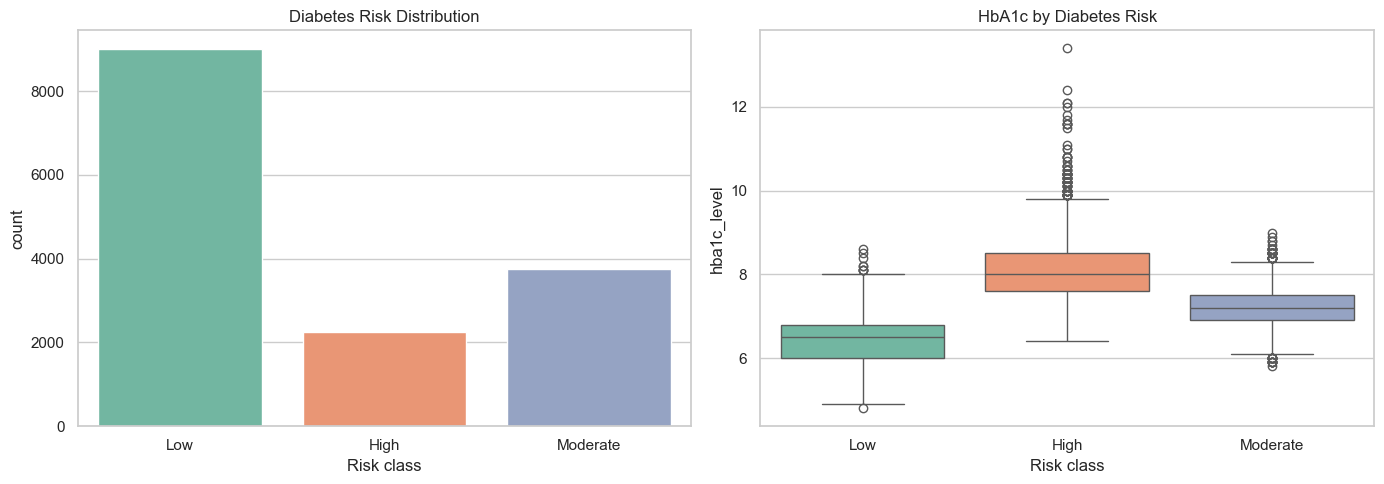

<Figure size 1000x500 with 0 Axes>

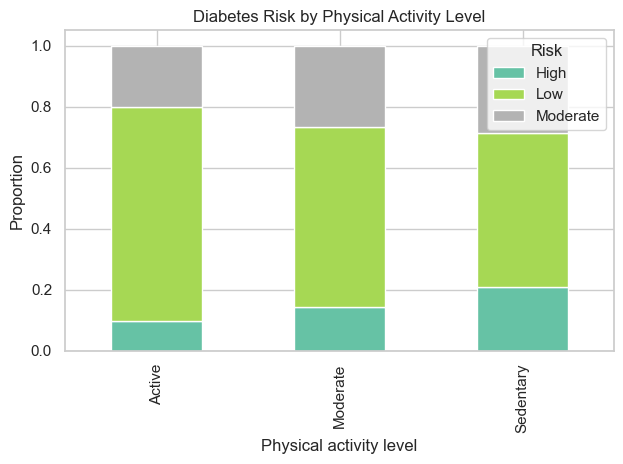

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=data, x="diabetes_risk", ax=axes[0], palette="Set2")
axes[0].set_title("Diabetes Risk Distribution")
axes[0].set_xlabel("Risk class")

sns.boxplot(data=data, x="diabetes_risk", y="hba1c_level",
            ax=axes[1], palette="Set2")
axes[1].set_title("HbA1c by Diabetes Risk")
axes[1].set_xlabel("Risk class")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
activity_risk = pd.crosstab(data["physical_activity_level"],
                            data["diabetes_risk"], normalize="index")
activity_risk.plot(kind="bar", stacked=True, colormap="Set2")
plt.title("Diabetes Risk by Physical Activity Level")
plt.xlabel("Physical activity level")
plt.ylabel("Proportion")
plt.legend(title="Risk")
plt.tight_layout()
plt.show()

## 5. Prepare Features and Target

`patient_id` is an identifier and is intentionally excluded from the model. The remaining columns are detected as numerical or categorical features.

In [7]:
target_column = "diabetes_risk"
excluded_columns = ["patient_id"]
feature_columns = [
    column for column in data.columns
    if column not in excluded_columns + [target_column]
]

X = data[feature_columns].copy()
y = data[target_column].copy()

model_numeric_columns = X.select_dtypes(include="number").columns.tolist()
model_categorical_columns = X.select_dtypes(exclude="number").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training rows: {len(X_train):,}")
print(f"Testing rows: {len(X_test):,}")
print("Numerical features:", model_numeric_columns)
print("Categorical features:", model_categorical_columns)

Training rows: 12,000
Testing rows: 3,000
Numerical features: ['age', 'bmi', 'hours_sleep_per_night', 'stress_level', 'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'waist_circumference_cm']
Categorical features: ['gender', 'city', 'family_history_diabetes', 'physical_activity_level', 'diet_type', 'smoking_status', 'alcohol_consumption', 'income_bracket']


## 6. Build and Train the Classification Pipeline

In [10]:
import numpy as np

X_train = X_train.copy()
X_test = X_test.copy()

for col in model_categorical_columns:
    X_train[col] = X_train[col].astype("object").where(X_train[col].notna(), np.nan)
    X_test[col] = X_test[col].astype("object").where(X_test[col].notna(), np.nan)

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numerical", numeric_preprocessor, model_numeric_columns),
    ("categorical", categorical_preprocessor, model_categorical_columns)
])

classifier = RandomForestClassifier(
    n_estimators=150,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

model_pipeline.fit(X_train, y_train)

print("Training complete.")

Training complete.


## 7. Evaluate the Model

In [11]:
predictions = model_pipeline.predict(X_test)
probabilities = model_pipeline.predict_proba(X_test)
class_labels = model_pipeline.named_steps["classifier"].classes_

metrics = {
    "accuracy": float(accuracy_score(y_test, predictions)),
    "precision_weighted": float(precision_score(y_test, predictions, average="weighted", zero_division=0)),
    "recall_weighted": float(recall_score(y_test, predictions, average="weighted", zero_division=0)),
    "f1_weighted": float(f1_score(y_test, predictions, average="weighted", zero_division=0)),
    "test_rows": int(len(y_test)),
    "classes": class_labels.tolist()
}

if len(class_labels) == 2:
    positive_class = "High" if "High" in class_labels else class_labels[1]
    positive_index = list(class_labels).index(positive_class)
    metrics["roc_auc"] = float(roc_auc_score(
        (y_test == positive_class).astype(int), probabilities[:, positive_index]
    ))

print(classification_report(y_test, predictions, zero_division=0))
print("Confusion matrix:")
display(pd.DataFrame(
    confusion_matrix(y_test, predictions, labels=class_labels),
    index=[f"Actual {label}" for label in class_labels],
    columns=[f"Predicted {label}" for label in class_labels]
))
display(pd.DataFrame([metrics]).round(4))

              precision    recall  f1-score   support

        High       0.80      0.69      0.74       450
         Low       0.85      0.91      0.88      1800
    Moderate       0.60      0.54      0.57       750

    accuracy                           0.79      3000
   macro avg       0.75      0.72      0.73      3000
weighted avg       0.78      0.79      0.78      3000

Confusion matrix:


,Predicted High,Predicted Low,Predicted Moderate
Actual High,312,13,125
Actual Low,5,1645,150
Actual Moderate,71,273,406


,accuracy,precision_weighted,recall_weighted,f1_weighted,test_rows,classes
0,0.7877,0.7808,0.7877,0.7826,3000,"[High, Low, Moderate]"


## 8. Save Model and Dashboard Data

The dashboard receives the cleaned data and metadata from `saved_data`. It does not need to load or process the original CSV.

In [12]:
dashboard_data = data.copy()

for column in model_numeric_columns:
    dashboard_data[column] = dashboard_data[column].fillna(dashboard_data[column].median())
for column in model_categorical_columns + [target_column]:
    if dashboard_data[column].isna().any():
        dashboard_data[column] = dashboard_data[column].fillna(
            dashboard_data[column].mode(dropna=True).iloc[0]
        )

joblib.dump(model_pipeline, SAVED_DATA_DIR / "diabetes_model.joblib")
dashboard_data.to_csv(SAVED_DATA_DIR / "processed_data.csv", index=False)

with open(SAVED_DATA_DIR / "model_metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)

feature_metadata = {
    "target_column": target_column,
    "excluded_columns": excluded_columns,
    "feature_columns": feature_columns,
    "numerical_features": model_numeric_columns,
    "categorical_features": model_categorical_columns,
    "target_classes": class_labels.tolist(),
    "row_count": int(len(dashboard_data)),
    "model": "RandomForestClassifier",
    "random_state": 42
}

with open(SAVED_DATA_DIR / "feature_metadata.json", "w", encoding="utf-8") as file:
    json.dump(feature_metadata, file, indent=2)

print("Saved files:")
for saved_file in sorted(SAVED_DATA_DIR.iterdir()):
    print(f"- {saved_file}")

Saved files:
- saved_data\diabetes_model.joblib
- saved_data\feature_metadata.json
- saved_data\model_metrics.json
- saved_data\processed_data.csv


## 9. Final Artifact Check

In [ ]:
required_files = [
    "diabetes_model.joblib",
    "processed_data.csv",
    "model_metrics.json",
    "feature_metadata.json"
]

missing_files = [
    filename for filename in required_files
    if not (SAVED_DATA_DIR / filename).exists()
]
assert not missing_files, f"Missing saved files: {missing_files}"
assert len(pd.read_csv(SAVED_DATA_DIR / "processed_data.csv")) == len(data)
print("All required artifacts exist and the saved dashboard data is ready for app.py.")

All required artifacts exist and the saved dashboard data is ready for app.py.
